In [1]:

!pip install nltk scikit-learn pandas matplotlib seaborn gradio -q

import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully!")



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...


Libraries imported successfully!


[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [2]:

data = {

    "symptoms": [
        "What are the common symptoms of heart disease?",
        "Why do I experience chest discomfort?",
        "What causes shortness of breath?",
        "Can heart problems cause dizziness?",
        "Why does my heart beat irregularly?",
        "What are signs of a heart attack?",
        "Can excessive sweating indicate heart problems?",
        "Why do I feel unusually tired?",
        "What causes palpitations?",
        "Can swelling in legs be related to heart problems?"
    ],

    "diseases": [
        "What is coronary artery disease?",
        "Explain congestive heart failure",
        "What is an irregular heartbeat?",
        "What is cardiomyopathy?",
        "Explain the meaning of arrhythmia",
        "What is a heart valve disease?",
        "What is an enlarged heart?",
        "Explain congenital heart disease",
        "What is angina?",
        "What is myocarditis?"
    ],

    "prevention": [
        "How can I maintain a healthy heart?",
        "What foods are good for heart health?",
        "How much exercise is good for the heart?",
        "How can I reduce heart disease risk?",
        "Is walking beneficial for heart health?",
        "What is a heart healthy diet?",
        "How does quitting smoking help the heart?",
        "Can yoga improve cardiovascular health?",
        "How can I maintain a healthy lifestyle?",
        "What habits improve heart health?"
    ],

    "risk_factors": [
        "Does high blood pressure affect the heart?",
        "How does cholesterol increase heart disease risk?",
        "Can smoking cause heart disease?",
        "Does obesity increase cardiovascular risk?",
        "Is diabetes a risk factor for heart disease?",
        "Can stress affect heart health?",
        "Does family history increase heart disease risk?",
        "How does alcohol affect the heart?",
        "Can lack of exercise increase heart risk?",
        "Does age increase the risk of heart disease?"
    ],

    "monitoring": [
        "What is a normal resting heart rate?",
        "How can I monitor my blood pressure?",
        "What is an ECG test?",
        "What does an echocardiogram measure?",
        "How often should blood pressure be checked?",
        "What is a normal blood pressure reading?",
        "How does a heart rate monitor work?",
        "What is cholesterol monitoring?",
        "What is a stress test for the heart?",
        "How can I track my heart health?"
    ]
}

# Convert dataset into a DataFrame

queries = []
labels = []

for intent, questions in data.items():
    for question in questions:
        queries.append(question)
        labels.append(intent)

df = pd.DataFrame({
    "query": queries,
    "intent": labels
})

print("Total queries:", len(df))
print("\nIntent distribution:")
print(df["intent"].value_counts())

df.head()


Total queries: 50

Intent distribution:
intent
symptoms        10
diseases        10
prevention      10
risk_factors    10
monitoring      10
Name: count, dtype: int64


,query,intent
0,What are the common symptoms of heart disease?,symptoms
1,Why do I experience chest discomfort?,symptoms
2,What causes shortness of breath?,symptoms
3,Can heart problems cause dizziness?,symptoms
4,Why does my heart beat irregularly?,symptoms


In [3]:

taxonomy = {

    "Heart Diseases": [
        "Coronary Artery Disease",
        "Heart Failure"
    ],

    "Symptoms": [
        "Chest Pain",
        "Breathlessness"
    ],

    "Prevention": [
        "Healthy Diet",
        "Physical Activity"
    ],

    "Risk Factors": [
        "High Blood Pressure",
        "High Cholesterol"
    ],

    "Heart Health Monitoring": [
        "Blood Pressure Monitoring",
        "Heart Rate Monitoring"
    ]
}

print("HEART HEALTH TAXONOMY\n")

for category, subcategories in taxonomy.items():
    print(category)

    for subcategory in subcategories:
        print("  ├──", subcategory)


HEART HEALTH TAXONOMY

Heart Diseases
  ├── Coronary Artery Disease
  ├── Heart Failure
Symptoms
  ├── Chest Pain
  ├── Breathlessness
Prevention
  ├── Healthy Diet
  ├── Physical Activity
Risk Factors
  ├── High Blood Pressure
  ├── High Cholesterol
Heart Health Monitoring
  ├── Blood Pressure Monitoring
  ├── Heart Rate Monitoring


In [4]:

concepts = {
    "Heart": "Organ responsible for pumping blood",
    "Blood Pressure": "Force exerted by blood against artery walls",
    "Cholesterol": "Fat-like substance present in blood",
    "Arteries": "Blood vessels carrying blood away from the heart",
    "Heart Rate": "Number of heartbeats per minute",
    "ECG": "Test that records electrical activity of the heart",
    "Exercise": "Physical activity supporting cardiovascular fitness",
    "Diet": "Food habits affecting cardiovascular health",
    "Smoking": "Habit that increases cardiovascular risk",
    "Diabetes": "Condition that can increase cardiovascular risk"
}

relationships = [
    ("Heart", "pumps", "Blood"),
    ("Arteries", "carry", "Blood"),
    ("High Blood Pressure", "increases strain on", "Heart"),
    ("High Cholesterol", "contributes to plaque in", "Arteries"),
    ("Smoking", "increases risk of damage to", "Heart"),
    ("Diabetes", "increases risk of", "Heart Disease"),
    ("Exercise", "supports health of", "Heart"),
    ("Diet", "influences", "Cholesterol"),
    ("ECG", "records electrical activity of", "Heart"),
    ("Heart Rate", "indicates activity of", "Heart")
]

print("DOMAIN CONCEPTS")

for concept, description in concepts.items():
    print(concept, ":", description)

print("\nDOMAIN RELATIONSHIPS")

for relation in relationships:
    print(relation[0], "-->", relation[1], "-->", relation[2])


DOMAIN CONCEPTS
Heart : Organ responsible for pumping blood
Blood Pressure : Force exerted by blood against artery walls
Cholesterol : Fat-like substance present in blood
Arteries : Blood vessels carrying blood away from the heart
Heart Rate : Number of heartbeats per minute
ECG : Test that records electrical activity of the heart
Exercise : Physical activity supporting cardiovascular fitness
Diet : Food habits affecting cardiovascular health
Smoking : Habit that increases cardiovascular risk
Diabetes : Condition that can increase cardiovascular risk

DOMAIN RELATIONSHIPS
Heart --> pumps --> Blood
Arteries --> carry --> Blood
High Blood Pressure --> increases strain on --> Heart
High Cholesterol --> contributes to plaque in --> Arteries
Smoking --> increases risk of damage to --> Heart
Diabetes --> increases risk of --> Heart Disease
Exercise --> supports health of --> Heart
Diet --> influences --> Cholesterol
ECG --> records electrical activity of --> Heart
Heart Rate --> indicates ac

In [5]:

lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words("english"))

# Preserve important negation words
stop_words = stop_words - {"no", "not", "nor"}

def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


df["processed_query"] = df["query"].apply(preprocess_text)

print(df[["query", "processed_query"]].head(10))


                                               query  \
0     What are the common symptoms of heart disease?   
1              Why do I experience chest discomfort?   
2                   What causes shortness of breath?   
3                Can heart problems cause dizziness?   
4                Why does my heart beat irregularly?   
5                  What are signs of a heart attack?   
6    Can excessive sweating indicate heart problems?   
7                     Why do I feel unusually tired?   
8                          What causes palpitations?   
9  Can swelling in legs be related to heart probl...   

                             processed_query  
0               common symptom heart disease  
1                experience chest discomfort  
2                     cause shortness breath  
3              heart problem cause dizziness  
4                     heart beat irregularly  
5                          sign heart attack  
6  excessive sweating indicate heart problem  
7      

In [6]:

# Separate features and labels

X = df["processed_query"]
y = df["intent"]

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Apply TF-IDF

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=2000
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

# Train Logistic Regression classifier

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Model trained successfully!
Training samples: 40
Testing samples: 10


MODEL EVALUATION RESULTS
------------------------
Accuracy: 0.9
Precision: 0.9333
Recall: 0.9
F1 Score: 0.8933

Classification Report:

              precision    recall  f1-score   support

    diseases       1.00      0.50      0.67         2
  monitoring       1.00      1.00      1.00         2
  prevention       0.67      1.00      0.80         2
risk_factors       1.00      1.00      1.00         2
    symptoms       1.00      1.00      1.00         2

    accuracy                           0.90        10
   macro avg       0.93      0.90      0.89        10
weighted avg       0.93      0.90      0.89        10



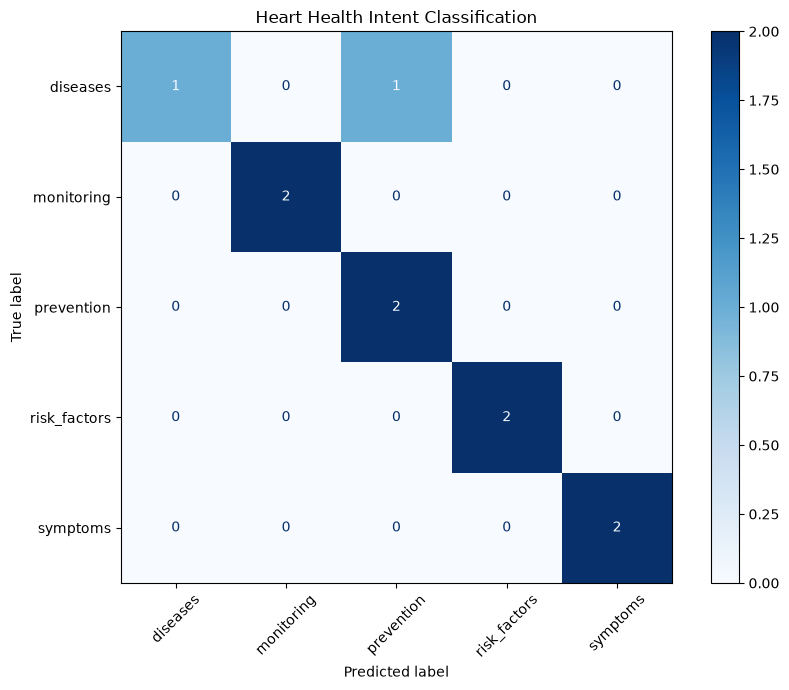

In [7]:

# Predict test labels

y_pred = model.predict(X_test_tfidf)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)

plt.title("Heart Health Intent Classification")
plt.tight_layout()
plt.show()


In [8]:

knowledge_base = {

    "symptoms": {
        "title": "Heart Disease Symptoms",
        "information": """
        Common symptoms associated with heart conditions include
        chest discomfort, breathlessness, palpitations, unusual
        fatigue, dizziness and swelling in the legs.

        Symptoms vary between individuals. Some heart conditions
        may have no obvious symptoms.

        Severe or sudden symptoms may require emergency medical care.
        """
    },

    "diseases": {
        "title": "Heart Diseases",
        "information": """
        Coronary artery disease occurs when the coronary arteries
        become narrowed or blocked.

        Heart failure is a condition in which the heart cannot
        pump blood as effectively as the body needs.

        Arrhythmia refers to an irregular heartbeat.

        Other conditions include cardiomyopathy, valve disease
        and myocarditis.
        """
    },

    "prevention": {
        "title": "Heart Disease Prevention",
        "information": """
        Heart health can be supported through balanced nutrition,
        regular physical activity, adequate sleep and avoiding
        tobacco products.

        Limiting excess salt and saturated fats can support
        cardiovascular health.

        Regular health checkups can help identify risk factors.
        """
    },

    "risk_factors": {
        "title": "Heart Disease Risk Factors",
        "information": """
        Important cardiovascular risk factors include high blood
        pressure, high cholesterol, diabetes, smoking, obesity,
        physical inactivity, increasing age and family history.

        Some risk factors can be managed through lifestyle changes
        and appropriate medical care.
        """
    },

    "monitoring": {
        "title": "Heart Health Monitoring",
        "information": """
        Heart health monitoring may involve measuring blood
        pressure, checking resting heart rate and monitoring
        cholesterol levels.

        An ECG records the electrical activity of the heart.

        An echocardiogram uses ultrasound to examine the heart's
        structure and pumping function.

        A healthcare professional can recommend appropriate tests.
        """
    }
}

print("Knowledge base created successfully!")

for key, value in knowledge_base.items():
    print(key, ":", value["title"])


Knowledge base created successfully!
symptoms : Heart Disease Symptoms
diseases : Heart Diseases
prevention : Heart Disease Prevention
risk_factors : Heart Disease Risk Factors
monitoring : Heart Health Monitoring


In [9]:

# Emergency-related phrases

emergency_phrases = [
    "severe chest pain",
    "crushing chest pain",
    "chest pain with sweating",
    "chest pain with nausea",
    "sudden shortness of breath",
    "sudden difficulty breathing",
    "fainting",
    "passed out",
    "sudden weakness on one side",
    "sudden trouble speaking",
    "severe chest pressure"
]

# Heart-health domain keywords

heart_keywords = [
    "heart", "cardiac", "cardiovascular",
    "blood pressure", "cholesterol", "pulse",
    "heartbeat", "heart rate", "artery",
    "arteries", "ecg", "ekg", "angina",
    "arrhythmia", "palpitation", "cardiomyopathy",
    "heart failure", "heart attack", "coronary",
    "exercise", "smoking", "diabetes",
    "diet", "blood vessel", "blood vessels"
]


def is_emergency(query):

    query = query.lower()

    for phrase in emergency_phrases:
        if phrase in query:
            return True

    return False


def is_heart_related(query):

    query = query.lower()

    for keyword in heart_keywords:
        if keyword in query:
            return True

    return False


print("Reasoning rules initialized!")


Reasoning rules initialized!


In [10]:

def heart_health_assistant(query):

    if not query.strip():
        return "Please enter a question."

    # RULE 1: Emergency escalation
    if is_emergency(query):

        return """
        EMERGENCY ALERT

        Your query mentions symptoms that may indicate
        a medical emergency.

        Call emergency services immediately (112 in India)
        or go to the nearest emergency department.

        Do not wait for an online response or attempt
        self-diagnosis.

        This assistant cannot provide emergency treatment.
        """

    # RULE 2: Unsupported query handling
    if not is_heart_related(query):

        return """
        UNSUPPORTED QUERY

        I am a Heart Health Information Assistant.

        I can help with:
        1. Heart disease symptoms
        2. Heart diseases
        3. Heart disease prevention
        4. Cardiovascular risk factors
        5. Heart health monitoring

        Please ask a heart-health-related question.
        """

    # Preprocess user query
    processed_query = preprocess_text(query)

    # Convert query into TF-IDF features
    query_vector = vectorizer.transform([processed_query])

    # Predict intent
    predicted_intent = model.predict(query_vector)[0]

    # Calculate confidence
    probabilities = model.predict_proba(query_vector)[0]

    confidence = max(probabilities)

    # RULE 3: Low-confidence handling
    if confidence < 0.35:

        return """
        LOW CONFIDENCE

        I could not confidently understand your question.

        Please rephrase your question or ask about:
        symptoms, diseases, prevention, risk factors
        or heart health monitoring.
        """

    # RULE 4: Knowledge retrieval
    result = knowledge_base[predicted_intent]

    # RULE 5: Safety disclaimer
    response = f"""
    HEART HEALTH INFORMATION ASSISTANT

    Detected Intent: {predicted_intent}

    Confidence: {confidence:.2f}

    Topic: {result['title']}

    Information:
    {result['information']}

    MEDICAL DISCLAIMER:
    This information is for educational purposes only.
    It is not a medical diagnosis or substitute for
    professional medical advice.
    Consult a qualified healthcare professional.
    """

    return response


print("Assistant integration completed!")


Assistant integration completed!


In [11]:

test_queries = [

    # 1. Query belonging to a defined intent
    "What foods are good for heart health?",

    # 2. Differently worded query
    "How do I keep my cardiovascular system healthy?",

    # 3. Unsupported healthcare query
    "What are the symptoms of a common cold?",

    # 4. Low-confidence query
    "Heart xyz blorpt quasar flibbertigibbet",

    # 5. Emergency-related query
    "I have severe chest pain with sweating"
]

for i, query in enumerate(test_queries):

    print("\n" + "=" * 60)
    print("TEST CASE", i + 1)
    print("User Query:", query)
    print("=" * 60)

    response = heart_health_assistant(query)

    print(response)



TEST CASE 1
User Query: What foods are good for heart health?

        LOW CONFIDENCE

        I could not confidently understand your question.

        Please rephrase your question or ask about:
        symptoms, diseases, prevention, risk factors
        or heart health monitoring.
        

TEST CASE 2
User Query: How do I keep my cardiovascular system healthy?

        LOW CONFIDENCE

        I could not confidently understand your question.

        Please rephrase your question or ask about:
        symptoms, diseases, prevention, risk factors
        or heart health monitoring.
        

TEST CASE 3
User Query: What are the symptoms of a common cold?

        UNSUPPORTED QUERY

        I am a Heart Health Information Assistant.

        I can help with:
        1. Heart disease symptoms
        2. Heart diseases
        3. Heart disease prevention
        4. Cardiovascular risk factors
        5. Heart health monitoring

        Please ask a heart-health-related question.
   

In [ ]:

with gr.Blocks(title="Heart Health Cognitive Assistant") as demo:

    gr.Markdown(
        """
        # Heart Health Information Assistant

        ### Your AI-powered cardiovascular information assistant

        Ask questions about heart diseases, symptoms,
        prevention, risk factors and heart health monitoring.

        **Note:** This assistant provides educational information
        and does not replace professional medical advice.
        """
    )

    user_input = gr.Textbox(
        label="Enter your question",
        placeholder="Example: How can I maintain a healthy heart?",
        lines=3
    )

    submit_button = gr.Button(
        "Get Answer",
        variant="primary"
    )

    output = gr.Textbox(
        label="Assistant Response",
        lines=12,
        interactive=False
    )

    submit_button.click(
        fn=heart_health_assistant,
        inputs=user_input,
        outputs=output
    )

    user_input.submit(
        fn=heart_health_assistant,
        inputs=user_input,
        outputs=output
    )

demo.launch(share=True)
